<a href="https://colab.research.google.com/github/Shaunblast/Iris_Classify_Neural_Network/blob/main/Iris_Classify_NeuralNetwork_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as nnf
import pandas as pd
import numpy as ny
import matplotlib.pyplot as plt
%matplotlib inline


In [ ]:
#Create my Neural Network class that inherits nn.Module operator
class Model(nn.Module):

#Define a function that initializes and creates my models Neural Network input layer, hidden layer
# and output layer
# input = 4 bc 4 parameters to deduce iris type
# h1 = 7 = number of neural nodes (neurons)
# h2 = 7 = number of neural nodes (neurons)
# h3 = 7 = number of neural nodes (neurons)
 def __init__(self, input_layer=4, h1=7, h2=7, h3=7, output_layer=3):
  super().__init__() # Instantiate my neural network

  # Define each layer of neural network (Linear model)
  self.fc1 = nn.Linear(input_layer, h1)
  self.fc2 = nn.Linear(h1, h2)
  self.fc3 = nn.Linear(h2, h3)
  self.out = nn.Linear(h3, output_layer)


 def forward(self, a): #Function to go forward through NN

  # a = To save info in variable between layers
  a = nnf.relu(self.fc1(a))
  a = nnf.relu(self.fc2(a))
  a = nnf.relu(self.fc3(a))
  a = self.out(a)

  # Relu (Rectified Linear Unit) is my activation function
  # Model is initialized and created at this point

  return a









In [ ]:
# Create a seed randomization for model
torch.manual_seed(41)

# Call an instance of model
model = Model()

In [ ]:
#Import and preprocess data for my nn model


url = 'https://gist.githubusercontent.com/netj/8836201/raw/6f9306ad21398ea43cba4f7d537619d0e07d5ae3/iris.csv'

data_form = pd.read_csv(url)

#ML works better w/ numbers = replace variety w/ numbers
data_form['variety'] = data_form['variety'].replace('Setosa', 0)
data_form['variety'] = data_form['variety'].replace('Versicolor', 1)
data_form['variety'] = data_form['variety'].replace('Virginica', 2)

data_form


/tmp/ipykernel_4892/1070089651.py:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_form['variety'] = data_form['variety'].replace('Virginica', 2)


,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [ ]:
# Set up training for NN

# Import test, train, split
from sklearn.model_selection import train_test_split

# Save the testing and training information to X & y variables
X = data_form.drop('variety', axis=1)
y = data_form['variety']


# Convert X and y values from data frame to numpy arrays for NN
X = X.values
y = y.values

# Load the testing and training data into the scikit-learn method train_test_split()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=41)




In [ ]:
# Convert from Numpy arrays to Tensors for NN
X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)
y_train = torch.LongTensor(y_train)
y_test = torch.LongTensor(y_test)



In [ ]:
# Set criterion for error/loss of prediction
criterion = nn.CrossEntropyLoss()

# Choose optimizer for learning rate and gradient backpropogation (Used Adam optimizer)
optimizer = torch.optim.Adam(model.parameters(), lr=0.009)
##NOTE TO SELF: When adding extra hidden layers, be sure the ReLU activation function is NOT severely negative because
##ReLU reads negative values as 0 and effectively will make my backpropagated gradients as "0"--effectively potentially
#making my neuron have a gradient of 0 throughthe ReLU function.


In [ ]:
#Setting the training parameters (epochs)

#Iterations of full training data
epochs = 100

##NOTE TO SELF: Once again, with more hidden layers and neurons, I need to be conscious of how my epochs
## and learning rates affect my loss/error when it comes to training my nn (and subsequently testing it)

#Keep track of losses

losses = []

#Sending predictions forward
for i in range(epochs):

  y_pred = model.forward(X_train) #Send the features of the flower through to get the prediction "y"

  # Measure the loss/error
  loss = criterion(y_pred, y_train) # Prediction versus actual y_train value

  losses.append(loss.detach().numpy()) # .detach and .numpy are needed to turn tensor back into numpy array and graph

  # Choose the intervals of epochs we want to print (to eventually graph)
  if i % 5 == 0:
    print(f'Epoch: {i} and loss: {loss}')



# Backpropogation for NN (Use the errors and gradients to change weights by sending information back through nn)
  optimizer.zero_grad() #This wipes the gradients clean from the previous epoch to backpropogate the correct changes
  loss.backward() #This loads the gradients to be sent backwards, but DOES NOT send the info back
  optimizer.step() #This is the method that sends the gradients back through the nn


Epoch: 0 and loss: 1.1447328329086304
Epoch: 5 and loss: 1.0535470247268677
Epoch: 10 and loss: 0.9715290069580078
Epoch: 15 and loss: 0.8619340658187866
Epoch: 20 and loss: 0.7266559600830078
Epoch: 25 and loss: 0.5898879766464233
Epoch: 30 and loss: 0.4839138686656952
Epoch: 35 and loss: 0.3984253704547882
Epoch: 40 and loss: 0.324513703584671
Epoch: 45 and loss: 0.2644510269165039
Epoch: 50 and loss: 0.20600217580795288
Epoch: 55 and loss: 0.15326641499996185
Epoch: 60 and loss: 0.11214181780815125
Epoch: 65 and loss: 0.08396966010332108
Epoch: 70 and loss: 0.06612514704465866
Epoch: 75 and loss: 0.05478428304195404
Epoch: 80 and loss: 0.047142066061496735
Epoch: 85 and loss: 0.04165923595428467
Epoch: 90 and loss: 0.03753621503710747
Epoch: 95 and loss: 0.034329961985349655


Text(0.5, 0, 'Epochs')

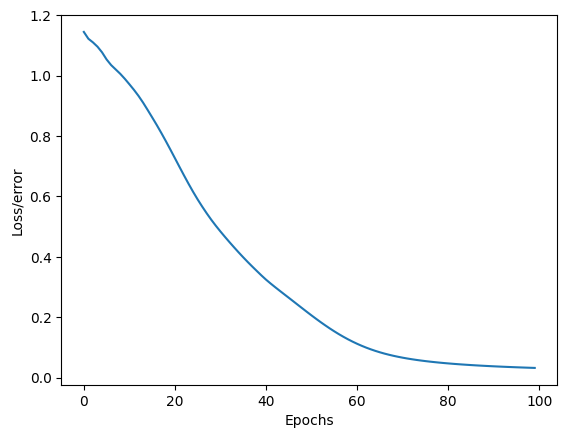

In [ ]:
#Plot my losses to visualize the learning rate (loss decrease)

plt.plot(range(epochs), losses)
plt.ylabel("Loss/error") # Change label of y axis
plt.xlabel("Epochs") # Change label of x axis

In [ ]:
#Prep to send Test data through (Turn off backpropagation)

with torch.no_grad(): #Turns off backpropagation
  y_eval = model.forward(X_test) #Sends data (test) forward through nn (X_test = flower features to get y predictions)

  loss = criterion(y_eval, y_test) #This will give me my loss/error for the trained model on my test data

  print(loss)




##This section is to get the number correct out of the total number of test data points--along with accuracy

correct = 0 # Variable to save NN correct choices


for i, index in enumerate(y_test): #Enumerate saves both the index and value of what is being looped through (y_test iris class)
    for a, index in enumerate(y_eval.argmax(axis=1)): #loop goes through each row of NN guess and outputs argmax for the iris class (being 0,1,2)
      if a == i: #Compares the individual values of the y_test and y_eval per EACH ROW
        correct += 1 #If correct adds 1 to my correct variable
      else: correct += 0 #If incorrect adds 0

##NOTE TO SELF: In above for loop, I ran into a problem where I tried to only use 1 for loop. Howevever, 2 for loops are needed because
## the boolean == is expecting only 1 think to compare to another thing. The argmax returns the all the rows of guesses the NN has down for the
## whole test batch. Therefore, the second for loop is needed in order to individually go through each row, pick the argmax, and compare it to
## the y_test value.

#Prints the number correct versus the total count of test data
print(f'Neural Network got {correct} out of {len(y_eval)} correct for an accuracy of {correct/len(y_eval)*100}%!')




tensor(0.1609)
Neural Network got 30 out of 30 correct for an accuracy of 100.0%!
